https://github.com/zalandoresearch/fashion-mnist#labels

In [2]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
import pandas as pd
import numpy as np

# The data has already been sorted into training and test sets for us
(train_data, train_labels), (test_data, test_labels) = fashion_mnist.load_data()

4422102/4422102 [==============================] - 0s 0us/step


In [2]:
# Check the shape of our data
train_data.shape, train_labels.shape, test_data.shape, test_labels.shape

((60000, 28, 28), (60000,), (10000, 28, 28), (10000,))

In [3]:
# Check shape of a single example
train_data[0].shape, train_labels[0].shape

((28, 28), ())

| Label | Description |
| ----- | ----------- |
| 0     | T-shirt/top |
| 1     | Trouser     |
| 2     | Pullover    |
| 3     | Dress       |
| 4     | Coat        |
| 5     | Sandal      |
| 6     | Shirt       |
| 7     | Sneaker     |
| 8     | Bag         |
| 9     | Ankle boot  |

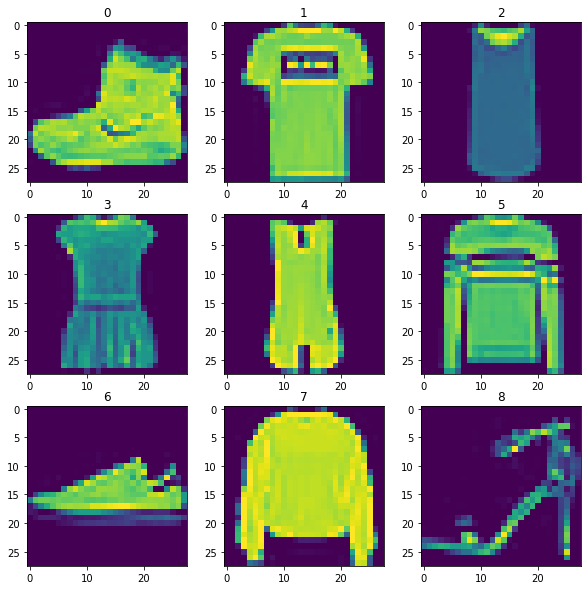

In [4]:
# Plot a single example
import matplotlib.pyplot as plt
fig, ax = plt.subplots(3,3)
fig.set_dpi = 300
fig.set_size_inches(10,10)
kk = 0
for ii in range(3):
    for jj in range(3):
        ax[ii,jj].imshow(train_data[kk])
        ax[ii,jj].set_title(kk)
        kk = kk + 1

In [5]:
train_labels.shape

(60000,)

In [8]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# How many classes are there (this'll be our output shape)?
len(class_names)

10

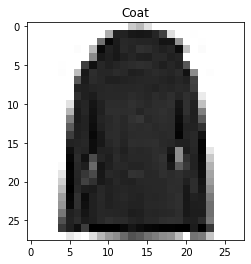

In [7]:
# Plot an example image and its label
index_of_choice = 2000
plt.imshow(train_data[index_of_choice], cmap=plt.cm.binary) # change the colours to black & white
plt.title(class_names[train_labels[index_of_choice]]);

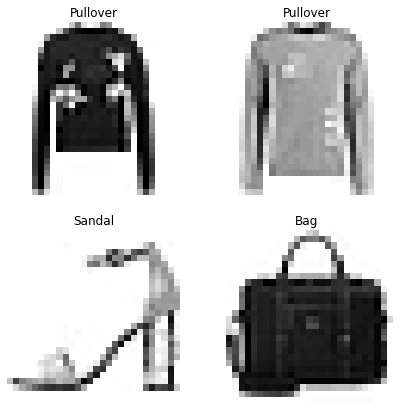

In [8]:
# Plot multiple random images of fashion MNIST
import random
plt.figure(figsize=(7, 7))
for i in range(4):
  ax = plt.subplot(2, 2, i + 1)
  rand_index = random.choice(range(len(train_data)))
  plt.imshow(train_data[rand_index], cmap=plt.cm.binary)
  plt.title(class_names[train_labels[rand_index]])
  plt.axis(False)

In [9]:
# Check shape of a single example
train_data.shape, train_labels.shape

((60000, 28, 28), (60000,))

In [10]:
# Check shape of a single example
train_data[0].shape, train_labels[0].shape

((28, 28), ())

In [11]:
tf.random.set_seed(42)

model_11 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28,28)), # nossos dados precisam se tornar um vetor de tamanho 28*25=784
    tf.keras.layers.Dense(4, activation="relu"),
    tf.keras.layers.Dense(4, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax") # temos 10 tipos de roupa
])

In [12]:
model_11.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    optimizer=tf.keras.optimizers.Adam(),
    metrics=["accuracy"]
)

In [13]:
non_norm_history = model_11.fit(
    train_data, train_labels,
    epochs=10, verbose=0,
    validation_data=(test_data, test_labels)
)

In [14]:
delta = train_data.max() - train_data.min()

# We can get our training and testing data between 0 & 1 by dividing by the maximum
train_data_norm = train_data / delta
test_data_norm = test_data / delta

# check the min and max values of the scaled training data
train_data_norm.min(), train_data_norm.max()

(0.0, 1.0)

In [15]:
# Now our data is normalized, let's build a model to find patterns in it

# Set random seed
tf.random.set_seed(42)

# Create a model (same as model_11)
model_12 = tf.keras.Sequential([
  tf.keras.layers.Flatten(input_shape=(28, 28)),
  tf.keras.layers.Dense(4, activation='relu'),
  tf.keras.layers.Dense(4, activation='relu'),
  tf.keras.layers.Dense(10, activation="softmax")
])

# Compile the model 
model_12.compile(loss=tf.keras.losses.SparseCategoricalCrossentropy(),
                 optimizer=tf.keras.optimizers.Adam(),
                 metrics=["accuracy"])

# Fit the model
norm_history = model_12.fit(train_data_norm,
                            train_labels,
                            epochs=10,
                            validation_data=(test_data_norm, test_labels))

Epoch 1/10
1875/1875 [==============================] - 6s 3ms/step - loss: 1.0348 - accuracy: 0.6474 - val_loss: 0.6937 - val_accuracy: 0.7617
Epoch 2/10
1875/1875 [==============================] - 5s 3ms/step - loss: 0.6376 - accuracy: 0.7757 - val_loss: 0.6400 - val_accuracy: 0.7820
Epoch 3/10
1875/1875 [==============================] - 4s 2ms/step - loss: 0.5942 - accuracy: 0.7914 - val_loss: 0.6247 - val_accuracy: 0.7783
Epoch 4/10
1875/1875 [==============================] - 4s 2ms/step - loss: 0.5750 - accuracy: 0.7979 - val_loss: 0.6078 - val_accuracy: 0.7881
Epoch 5/10
1875/1875 [==============================] - 4s 2ms/step - loss: 0.5641 - accuracy: 0.8006 - val_loss: 0.6169 - val_accuracy: 0.7881
Epoch 6/10
1875/1875 [==============================] - 4s 2ms/step - loss: 0.5544 - accuracy: 0.8043 - val_loss: 0.5855 - val_accuracy: 0.7951
Epoch 7/10
1875/1875 [==============================] - 4s 2ms/step - loss: 0.5488 - accuracy: 0.8063 - val_loss: 0.6097 - val_accuracy:

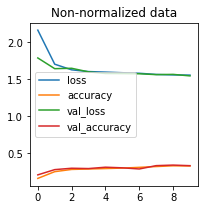

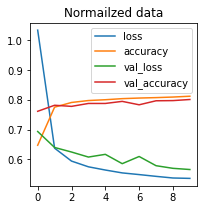

In [16]:
import pandas as pd 
# plt.rcParams["figure.dpi"] = 300
# Plot non-normalized data loss curves
pd.DataFrame(non_norm_history.history).plot(title="Non-normalized data", figsize=(3,3))
# Plot normalized data loss curves
pd.DataFrame(norm_history.history).plot(title="Normailzed data", figsize=(3,3))

In [17]:
model_11.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 784)               0         
                                                                 
 dense (Dense)               (None, 4)                 3140      
                                                                 
 dense_1 (Dense)             (None, 4)                 20        
                                                                 
 dense_2 (Dense)             (None, 10)                50        
                                                                 
Total params: 3,210
Trainable params: 3,210
Non-trainable params: 0
_________________________________________________________________


# Ideal learning rate

In [2]:
# Set random seed
tf.random.set_seed(42)

# Create model
model_13 = tf.keras.Sequential([
  tf.keras.layers.Flatten(input_shape=(28, 28)),
  tf.keras.layers.Dense(4, activation="relu"),
  tf.keras.layers.Dense(4, activation="relu"),
  tf.keras.layers.Dense(10, activation="softmax")
])

# Compile model
model_13.compile(loss=tf.keras.losses.SparseCategoricalCrossentropy(),
                 optimizer=tf.keras.optimizers.Adam(),
                 metrics=["accuracy"])

# Create the learning rate callback
lr_scheduler = tf.keras.callbacks.LearningRateScheduler(lambda epoch: 1e-10 * 10**(epoch/20))

# Fit the model
find_lr_history = model_13.fit(train_data_norm,
                               train_labels,
                               epochs=200,
                               validation_data=(test_data_norm, test_labels),
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
import pandas as pd
import numpy as np

# The data has already been sorted into training and test sets for us
(train_data, train_labels), (test_data, test_labels) = fashion_mnist.load_data()                               callbacks=[lr_scheduler])

SyntaxError: ignored

In [109]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
import pandas as pd
import numpy as np

# We can get our training and testing data between 0 & 1 by dividing by the maximum
train_data_norm = train_data / 255.0
test_data_norm = test_data / 255.0

# check the min and max values of the scaled training data
train_data_norm.min(), train_data_norm.max()


# Set random seed
tf.random.set_seed(42)

# Create model
model_13 = tf.keras.Sequential([
  tf.keras.layers.Flatten(input_shape=(28, 28)),
  tf.keras.layers.Dense(4, activation="relu"),
  tf.keras.layers.Dense(4, activation="relu"),
  tf.keras.layers.Dense(10, activation="softmax")
])

# Compile model
model_13.compile(loss=tf.keras.losses.SparseCategoricalCrossentropy(),
                 optimizer=tf.keras.optimizers.Adam(),
                 metrics=["accuracy"])

# Create the learning rate callback
lr_scheduler = tf.keras.callbacks.LearningRateScheduler(lambda epoch: 1e-4 * (10**(epoch/20)))

# Fit the model
epochs_ = 60
find_lr_history = model_13.fit(train_data_norm,
                               train_labels,
                               epochs=epochs_,
                               validation_data=(test_data_norm, test_labels),
                               callbacks=[lr_scheduler], verbose=0)

print("treinado")

treinado


In [110]:
# Plot the learning rate decay curve
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.pyplot as mpl

In [113]:
lrs = 1e-4 * (10**(tf.range(60)/20))
lrs.shape, np.array(find_lr_history.history["loss"]).shape

(TensorShape([60]), (60,))

Text(0.5, 1.0, 'Finding the ideal learning rate')

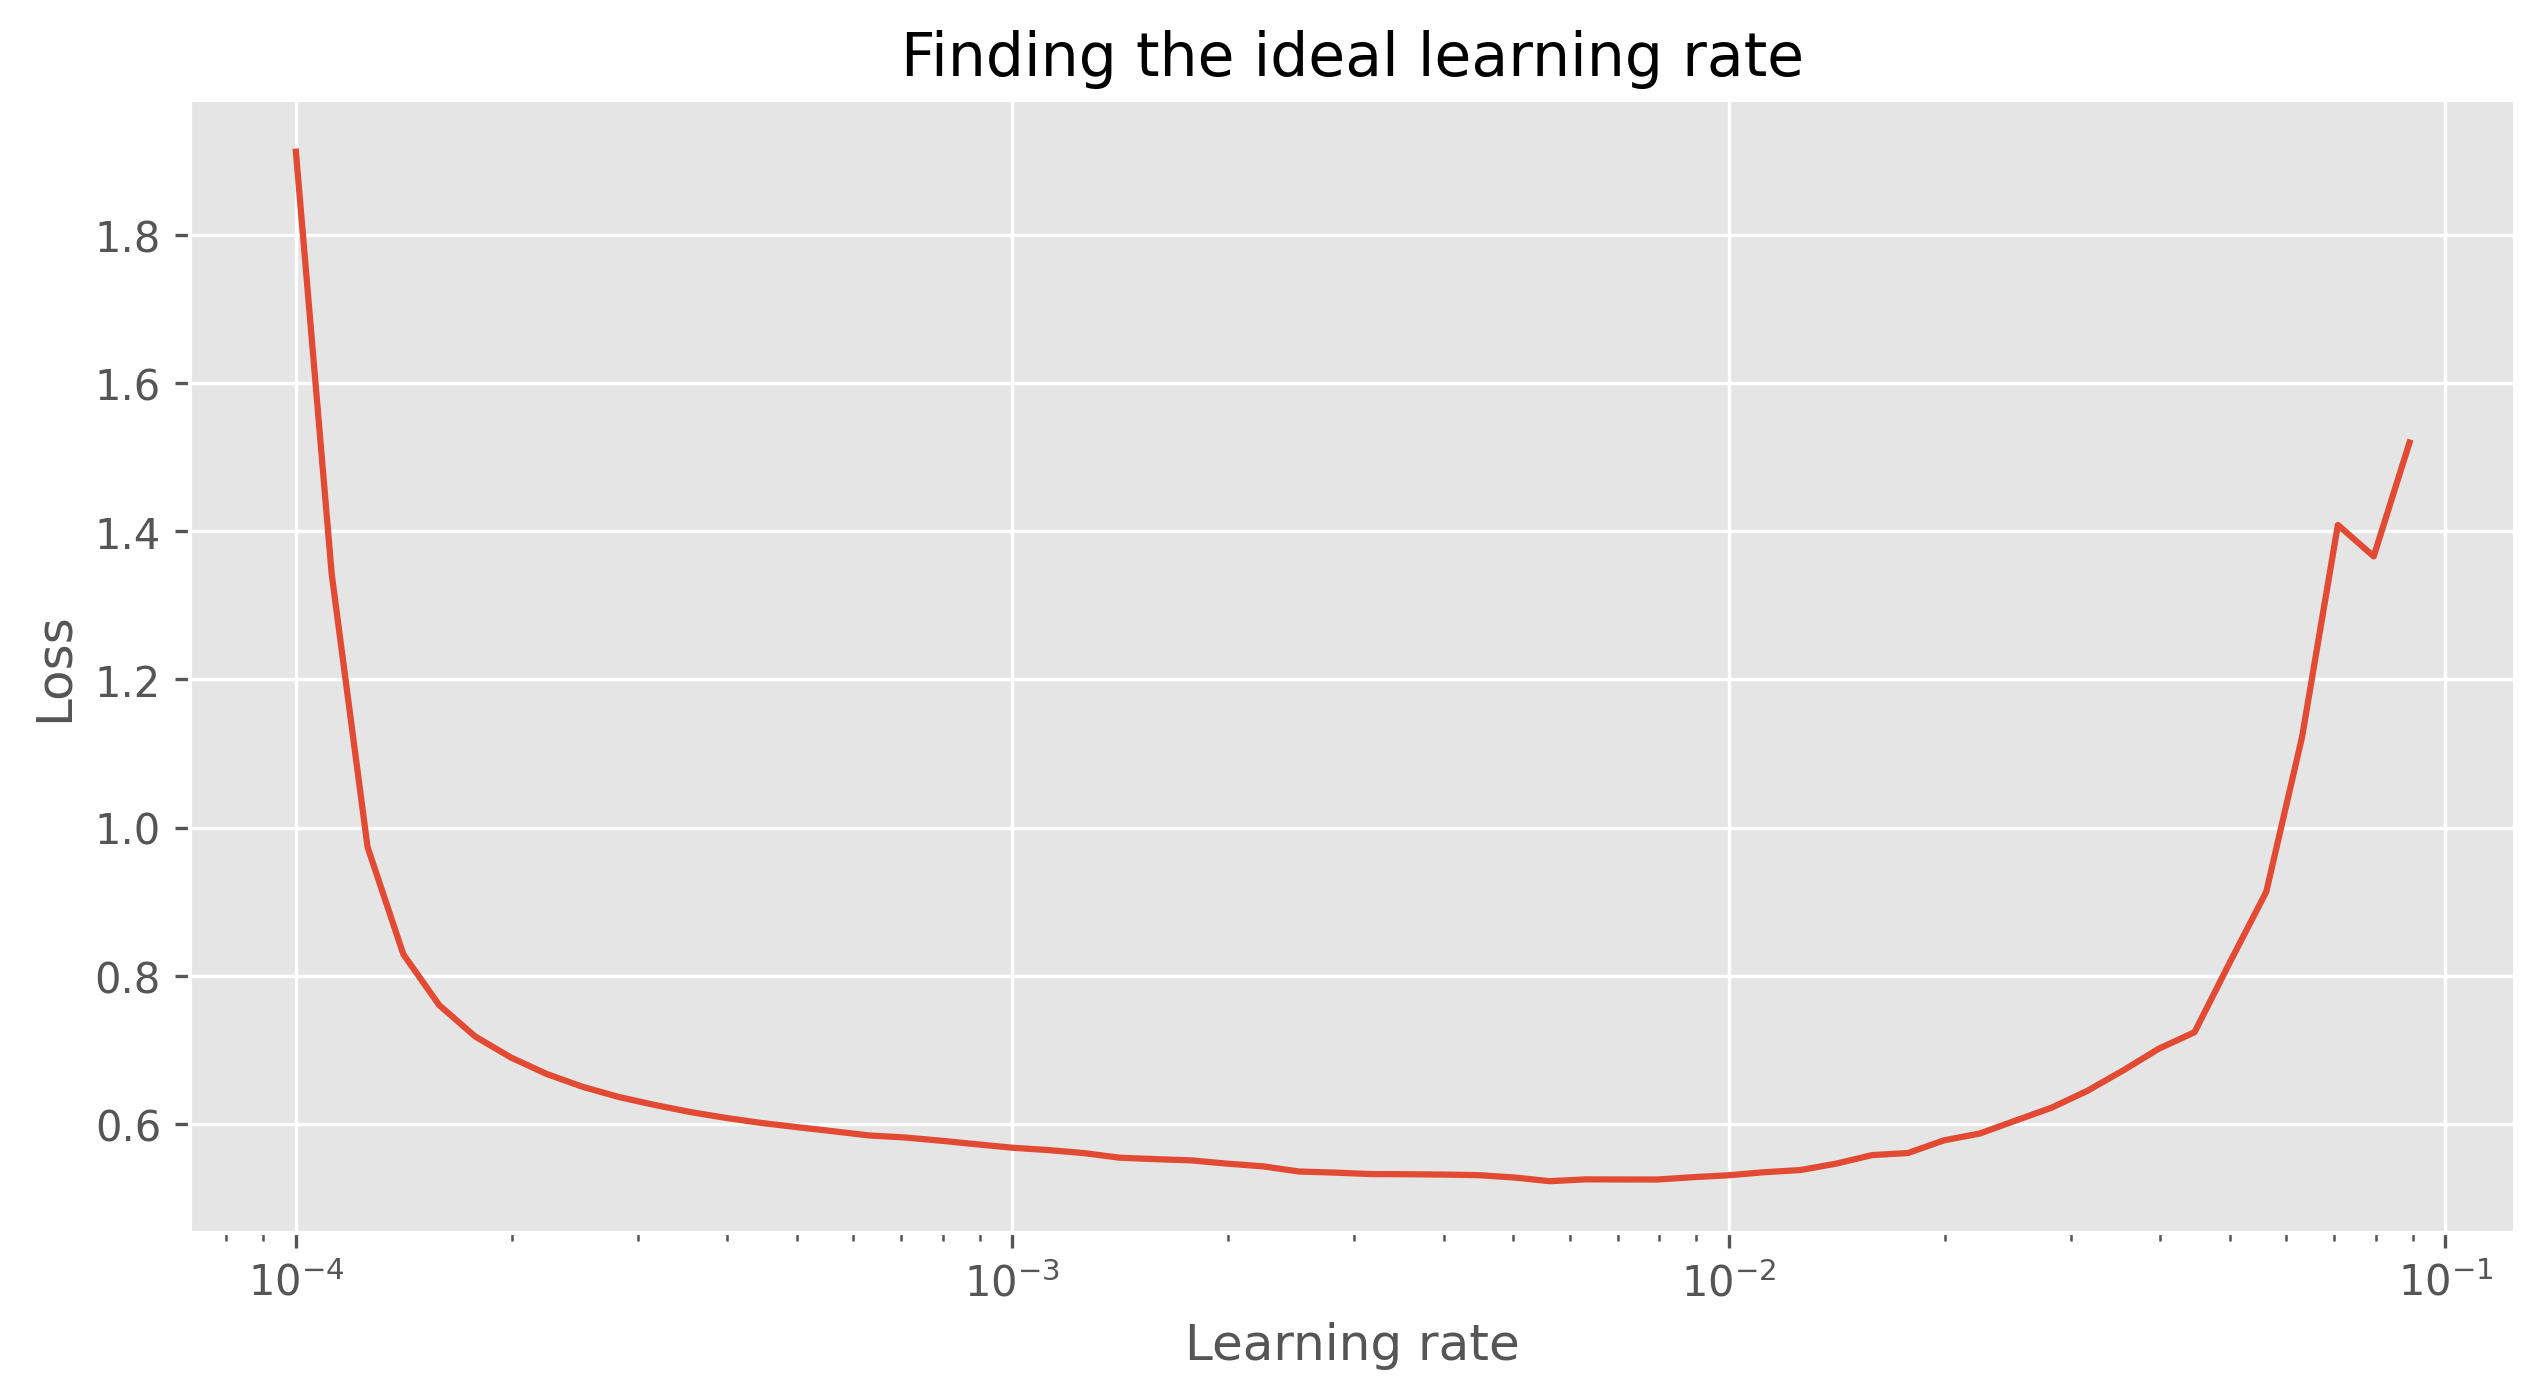

In [117]:
mpl.style.use('ggplot')
plt.figure(dpi=300, figsize=(10,5))
plt.semilogx(lrs, np.array(find_lr_history.history["loss"]))
plt.xlabel("Learning rate")
plt.ylabel("Loss")
plt.title("Finding the ideal learning rate")

In [ ]:
x = lrs
y = np.gradient(find_lr_history.history["loss"],x)
plt.semilogx(x, y)

In [4]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
import pandas as pd
import numpy as np

# We can get our training and testing data between 0 & 1 by dividing by the maximum
train_data_norm = train_data / 255.0
test_data_norm = test_data / 255.0

# check the min and max values of the scaled training data
train_data_norm.min(), train_data_norm.max()

(0.0, 1.0)

Epoch 1/20


/usr/local/lib/python3.7/dist-packages/keras/optimizers/optimizer_v2/adam.py:110: UserWarning: The `lr` argument is deprecated, use `learning_rate` instead.
  super(Adam, self).__init__(name, **kwargs)


1875/1875 [==============================] - 3s 2ms/step - loss: 2.2734 - accuracy: 0.1102 - val_loss: 2.2104 - val_accuracy: 0.1350
Epoch 2/20
1875/1875 [==============================] - 3s 2ms/step - loss: 2.1634 - accuracy: 0.1586 - val_loss: 2.1271 - val_accuracy: 0.1760
Epoch 3/20
1875/1875 [==============================] - 3s 2ms/step - loss: 2.0856 - accuracy: 0.1943 - val_loss: 2.0546 - val_accuracy: 0.2187
Epoch 4/20
1875/1875 [==============================] - 3s 2ms/step - loss: 2.0154 - accuracy: 0.2772 - val_loss: 1.9867 - val_accuracy: 0.3224
Epoch 5/20
1875/1875 [==============================] - 3s 2ms/step - loss: 1.9492 - accuracy: 0.3518 - val_loss: 1.9228 - val_accuracy: 0.3709
Epoch 6/20
1875/1875 [==============================] - 3s 2ms/step - loss: 1.8869 - accuracy: 0.3810 - val_loss: 1.8635 - val_accuracy: 0.3862
Epoch 7/20
1875/1875 [==============================] - 3s 2ms/step - loss: 1.8293 - accuracy: 0.3918 - val_loss: 1.8085 - val_accuracy: 0.3923
Epo

/usr/local/lib/python3.7/dist-packages/keras/optimizers/optimizer_v2/adam.py:110: UserWarning: The `lr` argument is deprecated, use `learning_rate` instead.
  super(Adam, self).__init__(name, **kwargs)


1875/1875 [==============================] - 5s 2ms/step - loss: 1.9126 - accuracy: 0.3121 - val_loss: 1.6130 - val_accuracy: 0.4120
Epoch 2/20
1875/1875 [==============================] - 3s 2ms/step - loss: 1.3692 - accuracy: 0.5155 - val_loss: 1.1722 - val_accuracy: 0.6266
Epoch 3/20
1875/1875 [==============================] - 3s 2ms/step - loss: 1.0230 - accuracy: 0.6708 - val_loss: 0.9483 - val_accuracy: 0.6826
Epoch 4/20
1875/1875 [==============================] - 3s 2ms/step - loss: 0.8742 - accuracy: 0.7010 - val_loss: 0.8562 - val_accuracy: 0.7003
Epoch 5/20
1875/1875 [==============================] - 3s 2ms/step - loss: 0.8038 - accuracy: 0.7220 - val_loss: 0.8039 - val_accuracy: 0.7216
Epoch 6/20
1875/1875 [==============================] - 3s 2ms/step - loss: 0.7617 - accuracy: 0.7360 - val_loss: 0.7721 - val_accuracy: 0.7311
Epoch 7/20
1875/1875 [==============================] - 3s 2ms/step - loss: 0.7335 - accuracy: 0.7455 - val_loss: 0.7475 - val_accuracy: 0.7380
Epo

/usr/local/lib/python3.7/dist-packages/keras/optimizers/optimizer_v2/adam.py:110: UserWarning: The `lr` argument is deprecated, use `learning_rate` instead.
  super(Adam, self).__init__(name, **kwargs)


1875/1875 [==============================] - 5s 2ms/step - loss: 1.0348 - accuracy: 0.6474 - val_loss: 0.6937 - val_accuracy: 0.7617
Epoch 2/20
1875/1875 [==============================] - 3s 2ms/step - loss: 0.6376 - accuracy: 0.7757 - val_loss: 0.6400 - val_accuracy: 0.7820
Epoch 3/20
1875/1875 [==============================] - 3s 2ms/step - loss: 0.5942 - accuracy: 0.7914 - val_loss: 0.6247 - val_accuracy: 0.7783
Epoch 4/20
1875/1875 [==============================] - 3s 2ms/step - loss: 0.5750 - accuracy: 0.7979 - val_loss: 0.6078 - val_accuracy: 0.7881
Epoch 5/20
1875/1875 [==============================] - 3s 2ms/step - loss: 0.5641 - accuracy: 0.8006 - val_loss: 0.6169 - val_accuracy: 0.7881
Epoch 6/20
1875/1875 [==============================] - 3s 2ms/step - loss: 0.5544 - accuracy: 0.8043 - val_loss: 0.5855 - val_accuracy: 0.7951
Epoch 7/20
1875/1875 [==============================] - 3s 2ms/step - loss: 0.5488 - accuracy: 0.8063 - val_loss: 0.6097 - val_accuracy: 0.7836
Epo

/usr/local/lib/python3.7/dist-packages/keras/optimizers/optimizer_v2/adam.py:110: UserWarning: The `lr` argument is deprecated, use `learning_rate` instead.
  super(Adam, self).__init__(name, **kwargs)


1875/1875 [==============================] - 4s 2ms/step - loss: 1.0987 - accuracy: 0.5718 - val_loss: 0.9617 - val_accuracy: 0.6553
Epoch 2/20
1875/1875 [==============================] - 3s 2ms/step - loss: 0.8661 - accuracy: 0.6932 - val_loss: 0.8452 - val_accuracy: 0.7093
Epoch 3/20
1875/1875 [==============================] - 3s 2ms/step - loss: 0.8399 - accuracy: 0.7001 - val_loss: 0.8149 - val_accuracy: 0.7089
Epoch 4/20
1875/1875 [==============================] - 3s 2ms/step - loss: 0.8276 - accuracy: 0.7054 - val_loss: 0.8251 - val_accuracy: 0.7037
Epoch 5/20
1875/1875 [==============================] - 3s 2ms/step - loss: 0.8201 - accuracy: 0.7060 - val_loss: 0.9053 - val_accuracy: 0.6706
Epoch 6/20
1875/1875 [==============================] - 3s 2ms/step - loss: 0.8157 - accuracy: 0.7085 - val_loss: 0.8032 - val_accuracy: 0.7090
Epoch 7/20
1875/1875 [==============================] - 3s 2ms/step - loss: 0.8051 - accuracy: 0.7094 - val_loss: 0.9451 - val_accuracy: 0.6581
Epo

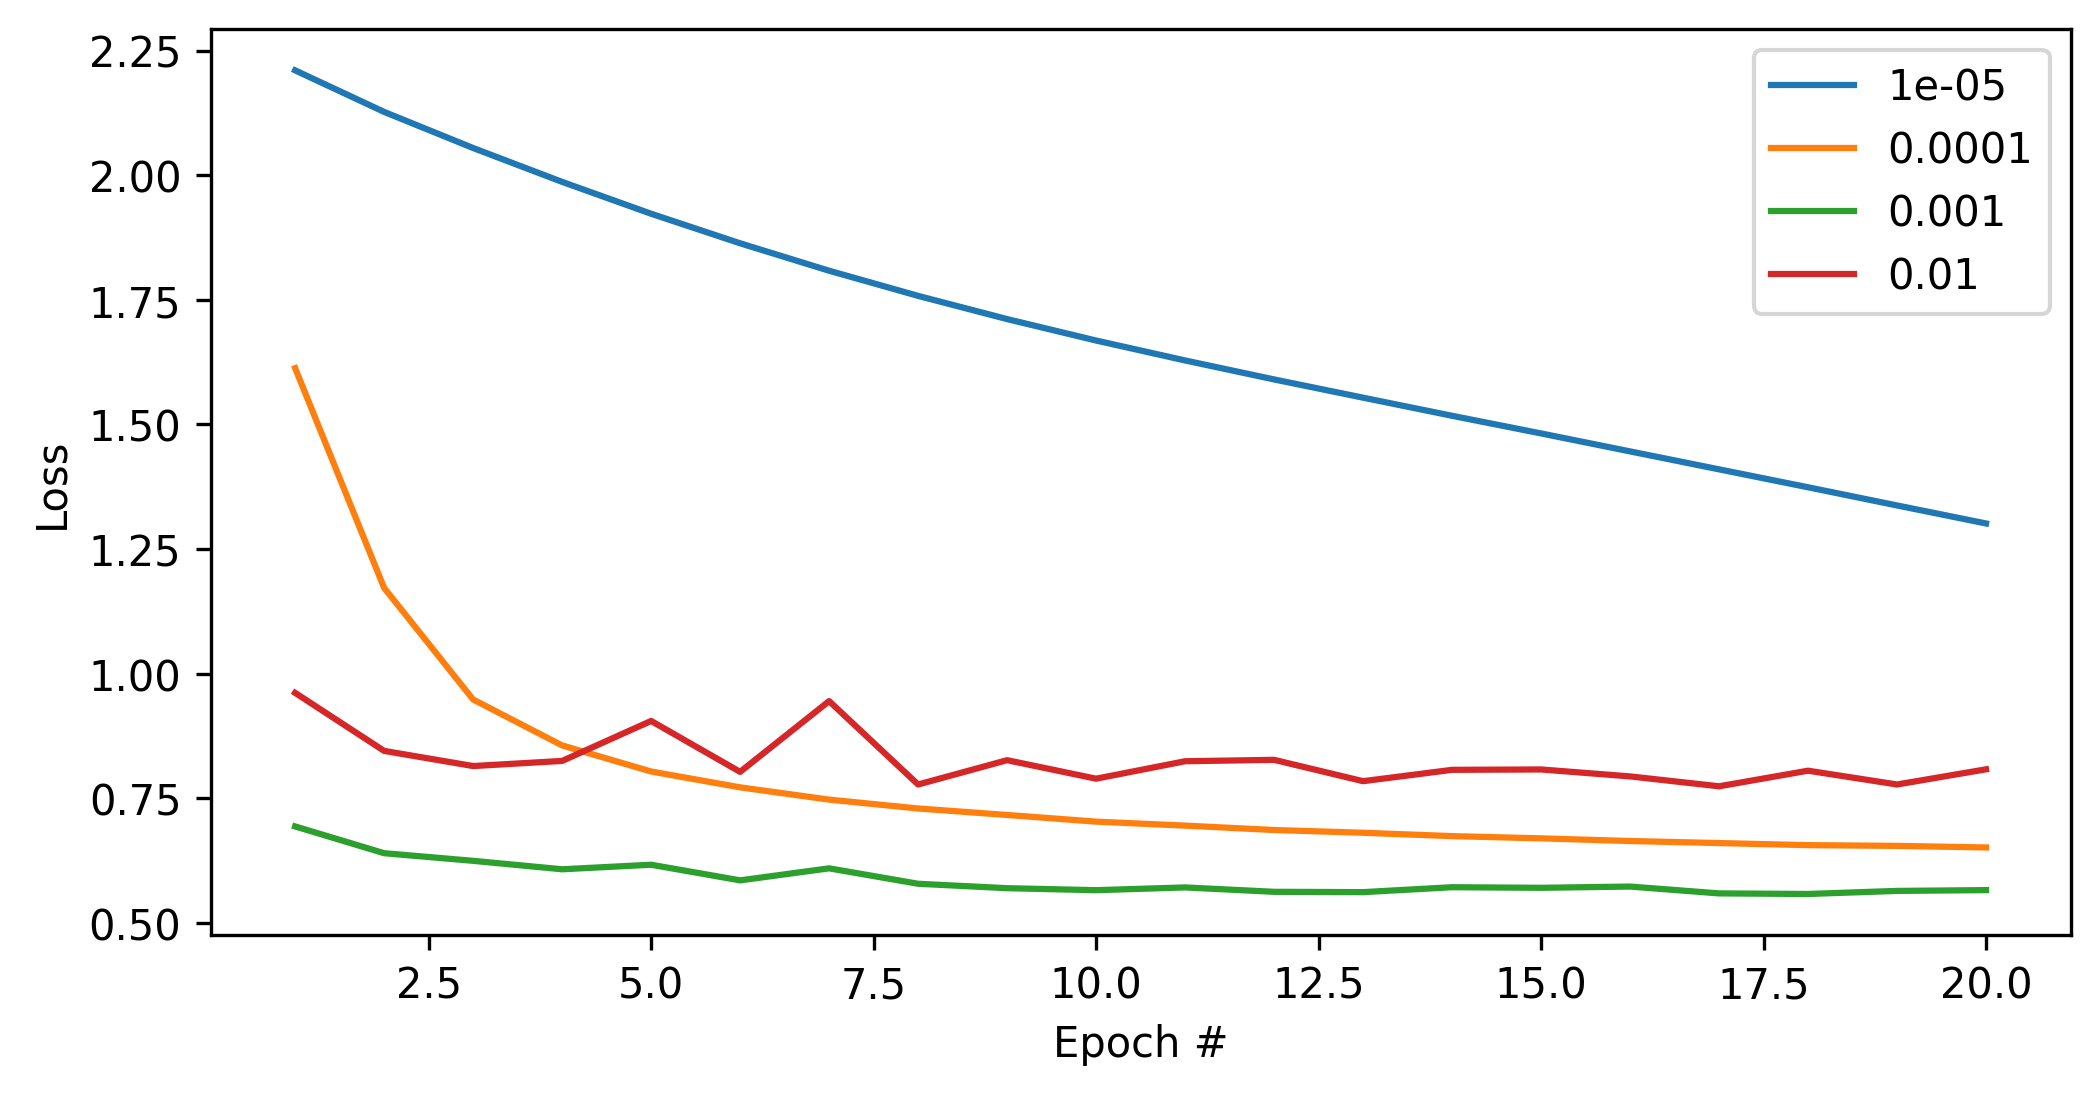

In [95]:
plt.figure(dpi=300, figsize=(8,4))
for kk in range(4):
    # Let's refit a model with the ideal learning rate

    # Set random seed
    tf.random.set_seed(42)

    # Create model
    model_14 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(4, activation="relu"),
    tf.keras.layers.Dense(4, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")                       
    ])

    epochs_ = 20
    # Compile model
    lr_=0.00001 * (10**kk)
    model_14.compile(loss=tf.keras.losses.SparseCategoricalCrossentropy(),
                    optimizer=tf.keras.optimizers.Adam(lr=lr_),
                    metrics=["accuracy"])

    # Fit the model
    history_14 = model_14.fit(train_data_norm,
                            train_labels,
                            epochs=epochs_,
                            validation_data=(test_data_norm, test_labels))
    
    yy = np.array(history_14.history['val_loss'])
    xx = np.arange(1, epochs_+1, 1)
    plt.plot(xx, yy, label=str(lr_))


plt.legend()
plt.xlabel('Epoch #')
plt.ylabel('Loss')
plt.show()

In [53]:
# Create a confusion matrix
import itertools
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt


def make_confusion_matrix(y_true, y_pred, classes=None, figsize=(10, 10), text_size=10, dpi=100):
  # Create the confusion matrix
  cm = confusion_matrix(y_true, y_pred)
  cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis] # normalize our confusion matrix
  n_classes = cm.shape[0]

  # Let's prettify it
  fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
  # Create a matrix plot
  cax = ax.matshow(cm, cmap=plt.cm.Blues)
  fig.colorbar(cax)

  # Set labels to be classes 
  if classes:
    labels = classes
  else:
    labels = np.arange(cm.shape[0])

  # Label the axes
  ax.set(title="Confusion Matrix",
        xlabel="Predicted Label",
        ylabel="True Label",
        xticks=np.arange(n_classes),
        yticks=np.arange(n_classes),
        xticklabels=labels, 
        yticklabels=labels)

  # Set x-axis labels to bottom
  ax.xaxis.set_label_position("bottom")
  ax.xaxis.tick_bottom()

  # Adjust label size
  ax.yaxis.label.set_size(text_size)
  ax.xaxis.label.set_size(text_size)
  ax.title.set_size(text_size)

  # Set threshold for different colors
  threshold = (cm.max() + cm.min()) / 2.

  # Plot the text on each cell
  for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(j, i, f"{cm[i, j]} ({cm_norm[i, j]*100:.1f}%)",
            horizontalalignment="center",
            color="white" if cm[i, j] > threshold else "black",
            size=text_size)

In [13]:
class_names, test_labels

(['T-shirt/top',
  'Trouser',
  'Pullover',
  'Dress',
  'Coat',
  'Sandal',
  'Shirt',
  'Sneaker',
  'Bag',
  'Ankle boot'],
 array([9, 2, 1, ..., 8, 1, 5], dtype=uint8))

In [14]:
# Make some predictions with our model 
y_probs = model_14.predict(test_data_norm) 
# probs is short for "prediction probabilities"

# View the first 5 predictions
y_probs[:5]
# remember that the output will also be normalized

313/313 [==============================] - 1s 1ms/step


array([[8.5629961e-11, 3.5361622e-13, 2.6633725e-05, 4.6356284e-08,
        5.0949748e-05, 9.6119456e-02, 8.1778026e-08, 9.1868833e-02,
        4.0605268e-03, 8.0787349e-01],
       [3.4278653e-06, 1.2899314e-16, 9.5989150e-01, 2.0516393e-07,
        1.5329231e-02, 2.4532665e-13, 2.4142833e-02, 1.1383622e-28,
        6.3272531e-04, 4.4789129e-08],
       [6.1062819e-05, 9.9657667e-01, 4.3866638e-08, 3.3405751e-03,
        1.3249396e-05, 1.4383215e-21, 8.2790139e-06, 7.3236619e-18,
        5.4811181e-08, 4.9224764e-14],
       [7.5031363e-05, 9.9053687e-01, 4.2528450e-07, 9.2231641e-03,
        1.3623103e-04, 1.8276370e-18, 2.6808191e-05, 4.8124370e-14,
        1.4521521e-06, 2.2211377e-11],
       [7.2189972e-02, 1.5495762e-06, 2.5566900e-01, 1.0363130e-02,
        4.3541361e-02, 1.1069341e-13, 6.1692995e-01, 6.7543104e-23,
        1.3049182e-03, 1.2140285e-09]], dtype=float32)

In [16]:
y_probs[0]

array([8.5629961e-11, 3.5361622e-13, 2.6633725e-05, 4.6356284e-08,
       5.0949748e-05, 9.6119456e-02, 8.1778026e-08, 9.1868833e-02,
       4.0605268e-03, 8.0787349e-01], dtype=float32)

In [19]:
postition_max_y_probs = tf.argmax(y_probs[0])
postition_max_y_probs

<tf.Tensor: shape=(), dtype=int64, numpy=9>

In [22]:
class_names[postition_max_y_probs]

'Ankle boot'

In [32]:
# Convert all of the prediction probabilities into integers
y_preds = y_probs.argmax(axis=1)

# View the first 10 prediction labels
y_preds[:20]

array([9, 2, 1, 1, 6, 1, 4, 6, 5, 7, 4, 5, 5, 3, 4, 1, 2, 6, 8, 0])

In [34]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_true=test_labels, y_pred=y_preds, dpi=300)

array([[696,   8,  25,  87,   9,   5, 160,   0,  10,   0],
       [  2, 939,   2,  35,   9,   0,  13,   0,   0,   0],
       [ 19,   2, 656,  10, 188,   0, 110,   0,  15,   0],
       [ 39,  10,  10, 819,  55,   0,  47,   1,  19,   0],
       [  0,   0,  95,  23, 800,   0,  73,   0,   7,   2],
       [  0,   0,   1,   0,   0, 894,   0,  60,   7,  38],
       [106,   4, 158,  57, 159,   1, 499,   0,  16,   0],
       [  0,   0,   0,   0,   0,  31,   0, 936,   0,  33],
       [  4,   1,  38,  15,   8,  12,   9,   5, 906,   2],
       [  0,   0,   1,   0,   2,  15,   0,  51,   1, 930]])

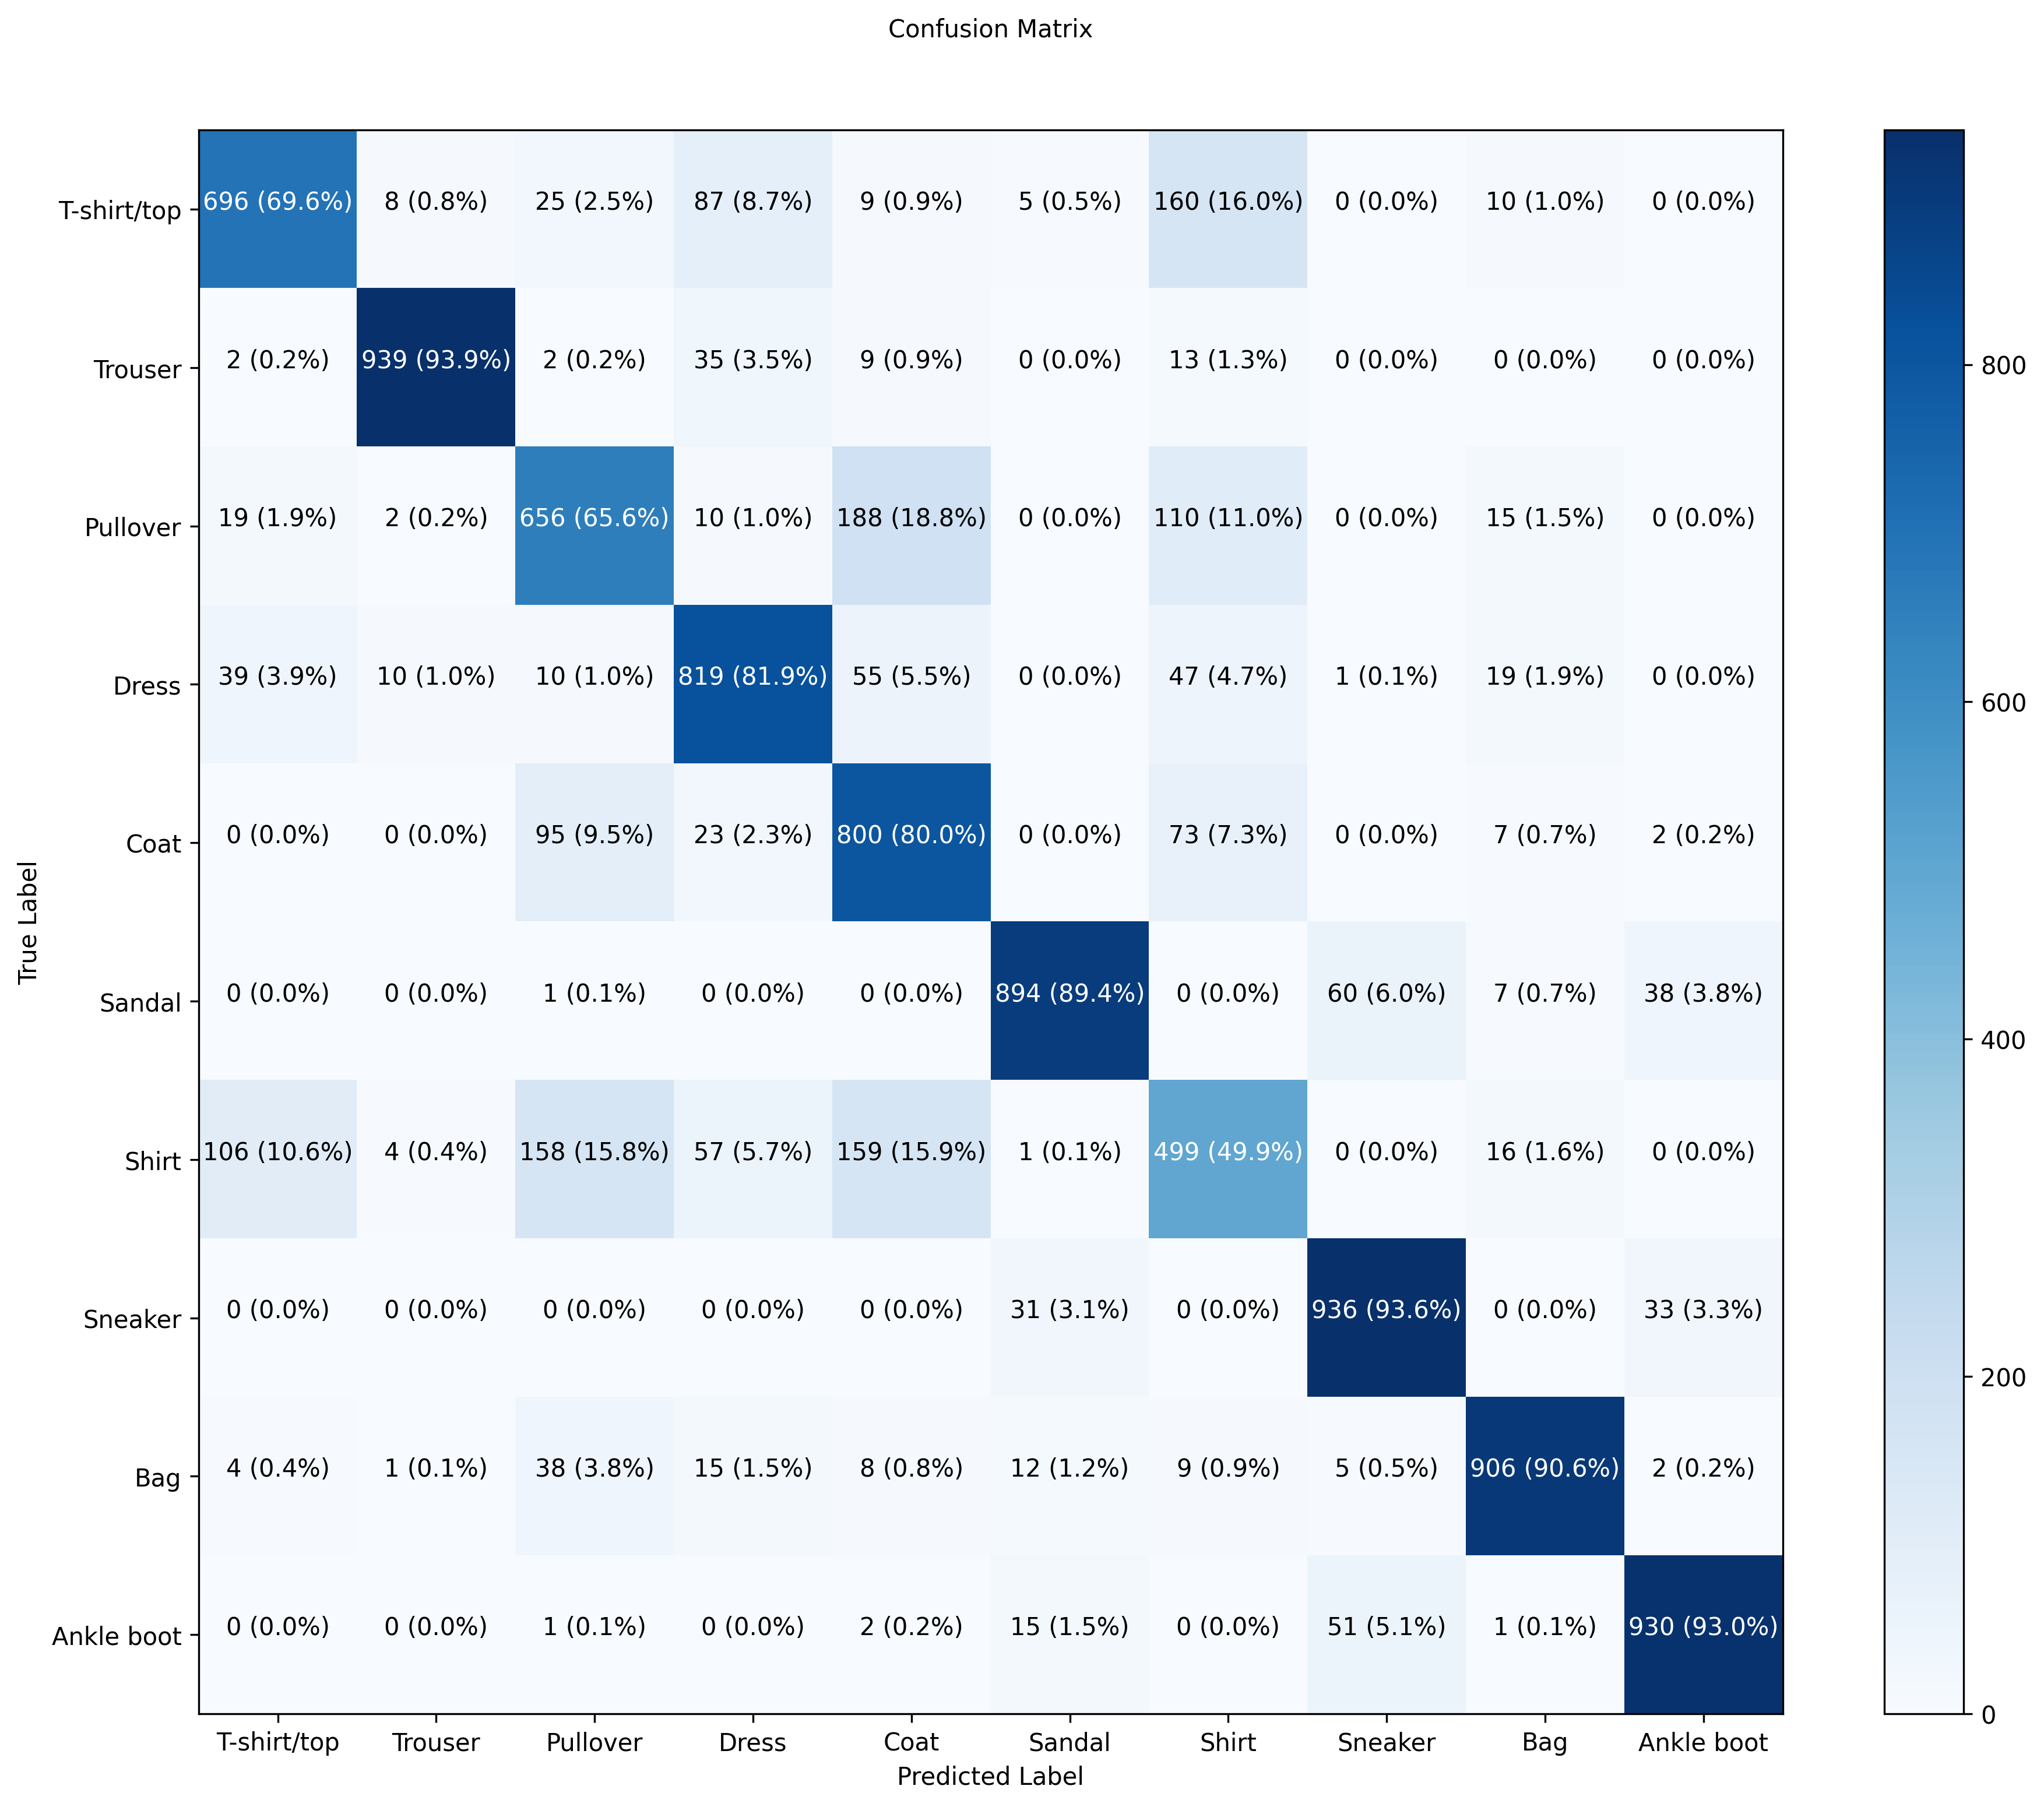

In [54]:
# Make a prettier confusion matrix
make_confusion_matrix(y_true=test_labels, y_pred=y_preds, classes=class_names, figsize=(15, 12), text_size=10, dpi=300)

In [118]:
import random

def plot_random_image(model, images, true_labels, classes):
  """
  Picks a random image, plots it and labels it with a prediction and truth label.
  """
  # Set up random integer
  i = random.randint(0, len(images))

  # Create predictions and targets
  target_image = images[i]
  pred_probs = model.predict(target_image.reshape(1, 28, 28))
  pred_label = classes[pred_probs.argmax()]
  true_label = classes[true_labels[i]]

  # Plot the image
  plt.imshow(target_image, cmap=plt.cm.binary)

  # Change the color of the titles depending on if the prediction is right or wrong
  if pred_label == true_label:
    color = "green"
  else:
    color = "red"
  
  # Add xlabel information (prediction/true label)
  plt.xlabel("Pred: {} {:2.0f}% (True: {})".format(pred_label,
                                                   100*tf.reduce_max(pred_probs),
                                                   true_label),
             color=color) # set the color to green or red based on if prediction is right or wrong

1/1 [==============================] - 0s 17ms/step


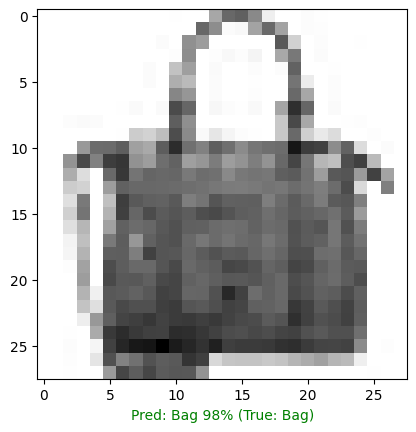

In [146]:
# Check out a random image as well as its prediction
mpl.style.use('default')
plt.rcParams["figure.dpi"] = 100
plot_random_image(model=model_14,
                  images=test_data_norm, # always make predictions on the same kind of data your model was trained on 
                  true_labels=test_labels,
                  classes=class_names)

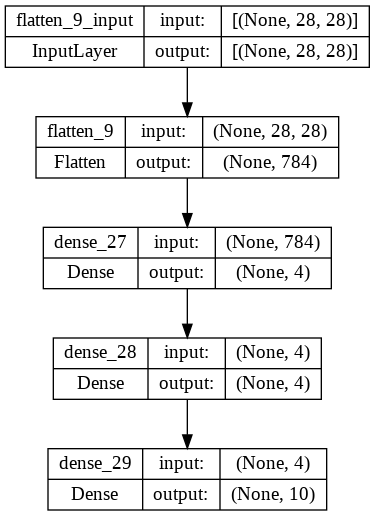

In [149]:
# Let's check out another way of viewing our deep learning models
from tensorflow.keras.utils import plot_model
# See the inputs and outputs of each layer
plot_model(model_14, show_shapes=True)